# SOFR Curve Built from Public Swap Trade Reports (DTCC)

A SOFR curve built only from free data has to guess its long end, usually Treasury yields plus an assumed swap spread. Every swap with a U.S. person, though, must be reported publicly within minutes. This notebook turns those raw trade reports into a curve, which is a real data-engineering problem, and in doing so replaces the guess with the swap spread the market actually traded.

**What it does.** It rebuilds the USD SOFR swap curve from thousands of real, anonymised swap trades reported to the DTCC swap data repository, with no dealer quotes and no assumptions about swap spreads.

**Data.** DTCC Public Price Dissemination cumulative rates files (CFTC jurisdiction, last 60 business days by default), the SOFR fixing (FRED) and the Treasury par curve (U.S. Treasury).

**Methods.** An ETL that filters and cleans raw trade reports, SQL aggregation with DuckDB, robust (Huber) estimation of the par swap rate per tenor and day, outlier flagging, and QuantLib bootstrapping.

**Key output.** A trade-based SOFR curve, its daily history, the **observed** swap spreads to Treasuries (which replace the usual textbook assumption) and a market-activity dashboard.

## 1. Why trade data

A SOFR curve built only from public rates data has to *assume* its long end: Treasury yields plus a guessed swap spread. That is fine for a sketch and not fine for a sign-off.

Since the Dodd-Frank reforms, every swap with a US person must be reported to a swap data repository, and its price is made public within minutes, anonymised and with large notionals capped. DTCC publishes one **cumulative file per day and asset class**, free to download. For USD rates that is tens of thousands of reports a day, a third of them SOFR swaps.

Turning those reports into a curve is a real data-engineering problem, the same one a risk team faces when it validates a vendor curve or a migration such as Numerix → Murex:

- reports include **corrections, cancellations, terminations and novations**, not just new trades;
- many trades are legs of **packages** (curve trades, spread-over-Treasury trades) whose individual rates are not clean market levels;
- some start in the future (**forward-starting**), and some have **non-standard maturities**;
- prices are noisy, so a few bad prints can drag a simple average.

The steps below handle each issue explicitly and record how many trades every filter removes.

## 2. Method in brief

1. **Extract.** Download the daily cumulative rates files, keep only USD SOFR OIS reports, and cache each day locally.
2. **Clean.**
   - Keep new trades (`NEWT` / `TRAD`) and drop any trade later reported as an error, correction or modification.
   - Drop package legs and non-standard terms.
   - Keep spot-starting swaps only, and map each maturity to a standard tenor (1Y … 30Y).
3. **Aggregate (SQL).** DuckDB summarises volume, trade counts and simple statistics by day and tenor.
4. **Estimate.** For each day and tenor, the par swap rate is a **Huber M-estimate** of the traded rates. It behaves like a mean for well-behaved prints and like a median when outliers appear. Trades more than 4 robust standard deviations away are flagged.
5. **Bootstrap.** QuantLib turns the latest day's par rates into a zero/forward curve, anchored at the overnight SOFR fixing.

$$
\hat\mu = \arg\min_\mu \sum_i \rho_c\!\left(\frac{r_i-\mu}{s}\right),
\qquad
\rho_c(u)=\begin{cases}\tfrac12 u^2 & |u|\le c\\ c|u|-\tfrac12c^2 & |u|>c\end{cases}
$$

with $s$ a robust scale (MAD) and $c=1.345$, which keeps 95% efficiency when the data are normal.

## 3. Setup

In [1]:
# --- Standard library
import datetime as dt
import io
import logging
import os
import re
import time
import warnings
import zipfile
from pathlib import Path

# --- Third-party
import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import QuantLib as ql
import requests
import statsmodels.api as sm
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
from tqdm.auto import tqdm

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

# --- Folders
PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
(DATA_DIR / "dtcc").mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

# --- Credentials
load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

# --- Analysis settings
# how many daily files to use (DTCC keeps roughly one year)
N_BUSINESS_DAYS = 60
STANDARD_TENORS = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 12, 15, 20, 25, 30]
# a maturity within ±1 month of a standard tenor is mapped to it
TENOR_TOLERANCE_Y = 0.08
# effective date at most 5 calendar days after execution = spot start
MAX_SPOT_LAG_DAYS = 5
# need at least this many trades for a robust rate
MIN_TRADES_PER_POINT = 3
# flag trades this many robust SDs from the estimate
OUTLIER_Z = 4.0

print(
    f"QuantLib {ql.__version__} · DuckDB {duckdb.__version__} · run on"
    f" {dt.date.today():%Y-%m-%d}"
)

QuantLib 1.44 · DuckDB 1.5.6 · run on 2026-10-20


In [2]:
# --- Caching helper (same idea as in every project of the repo)
def cached(name: str, fetch, max_age_hours: float = 12) -> pd.DataFrame:
    path = DATA_DIR / f"{name}.parquet"
    path.parent.mkdir(parents=True, exist_ok=True)
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
BLUE_RAMP = [
    "#f1f6fd",
    "#cde2fb",
    "#9ec5f4",
    "#6da7ec",
    "#3987e5",
    "#256abf",
    "#184f95",
    "#0d366b",
]
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

## 4. Extract: daily DTCC files

Each business day DTCC publishes
`https://kgc0418-tdw-data-0.s3.amazonaws.com/cftc/eod/CFTC_CUMULATIVE_RATES_<YYYY_MM_DD>.zip`
(also browsable at https://pddata.dtcc.com/ppd/cftcdashboard). One file is about 1–2 MB zipped.

For each day we keep only the **USD SOFR OIS** reports, identified by the product description `UPI FISN = "NA/Swap OIS USD"`, and only the columns we need. Values stay as raw text at this stage; parsing comes in the cleaning step. Past files never change, so cached days are reused indefinitely.

In [3]:
DTCC_URL = "https://kgc0418-tdw-data-0.s3.amazonaws.com/cftc/eod/CFTC_CUMULATIVE_RATES_{d:%Y_%m_%d}.zip"

RAW_COLUMNS = [
    "Dissemination Identifier",
    "Original Dissemination Identifier",
    "Action type",
    "Event type",
    "Execution Timestamp",
    "Effective Date",
    "Expiration Date",
    "Cleared",
    "Platform identifier",
    "Non-standardized term indicator",
    "Package indicator",
    "Notional amount-Leg 1",
    "Notional currency-Leg 1",
    "Fixed rate-Leg 1",
    "Fixed rate-Leg 2",
    "Fixed rate payment frequency period-Leg 1",
    "UPI FISN",
    "UPI Underlier Name",
]


def fetch_dtcc_day(day: dt.date) -> pd.DataFrame:
    """
    Download one daily file and keep the USD SOFR OIS reports (as raw text).
    """
    response = requests.get(DTCC_URL.format(d=day), timeout=90)
    response.raise_for_status()
    archive = zipfile.ZipFile(io.BytesIO(response.content))
    raw = pd.read_csv(
        archive.open(archive.namelist()[0]), dtype=str, low_memory=False
    )
    is_sofr_ois = raw["UPI FISN"].fillna("").str.contains(
        "Swap OIS USD"
    ) & raw["UPI Underlier Name"].fillna("").str.contains("SOFR", case=False)
    out = raw.loc[
        is_sofr_ois, [c for c in RAW_COLUMNS if c in raw.columns]
    ].copy()
    out["file_date"] = day.isoformat()
    return out


def collect_days(n_days: int) -> pd.DataFrame:
    """
    Walk back from yesterday over business days until n_days files are
    collected.
    """
    frames, day, attempts = [], dt.date.today(), 0
    progress = tqdm(total=n_days, desc="DTCC daily files")
    while len(frames) < n_days and attempts < int(n_days * 1.6) + 10:
        day -= dt.timedelta(days=1)
        if day.weekday() >= 5:
            continue
        attempts += 1
        try:
            frames.append(
                cached(
                    f"dtcc/{day:%Y_%m_%d}",
                    lambda: fetch_dtcc_day(day),
                    max_age_hours=24 * 365,
                )
            )
            progress.update(1)
        except (
            requests.HTTPError,
            requests.ConnectionError,
            requests.Timeout,
        ):
            # holiday, not yet published or a network hiccup: skip this day
            continue
    progress.close()
    return pd.concat(frames, ignore_index=True)


raw_reports = collect_days(N_BUSINESS_DAYS)
print(
    f"{raw_reports['file_date'].nunique()} daily files ·"
    f" {len(raw_reports):,} USD SOFR OIS reports"
    f" ({raw_reports['file_date'].min()} → {raw_reports['file_date'].max()})"
)
raw_reports.head(3)

DTCC daily files:   0%|          | 0/60 [00:00<?, ?it/s]

60 daily files · 296,429 USD SOFR OIS reports (2026-07-28 → 2026-10-19)


,Dissemination Identifier,Original Dissemination Identifier,Action type,Event type,Execution Timestamp,Effective Date,Expiration Date,Cleared,Platform identifier,Non-standardized term indicator,Package indicator,Notional amount-Leg 1,Notional currency-Leg 1,Fixed rate-Leg 1,Fixed rate-Leg 2,Fixed rate payment frequency period-Leg 1,UPI FISN,UPI Underlier Name,file_date
0,5847013174000000101,NaN,NEWT,TRAD,2026-10-19T20:58:30Z,2027-01-04,2029-01-04,I,BILT,NaN,FALSE,"45,000,000",USD,0.0468015,NaN,MNTH,NA/Swap OIS USD,USD-SOFR-OIS Compound,2026-10-19
1,5833938477000000101,NaN,NEWT,TRAD,2026-10-19T07:07:46Z,2026-10-21,2038-10-21,I,BBSF,FALSE,TRUE,"6,000,000",USD,0.047287,NaN,YEAR,NA/Swap OIS USD,USD-SOFR-COMPOUND,2026-10-19
2,5834275003000000101,NaN,NEWT,TRAD,2026-10-19T07:17:42Z,2026-10-21,2036-10-21,I,TSEF,FALSE,TRUE,"20,000,000",USD,NaN,0.0468081,NaN,NA/Swap OIS USD,USD-SOFR-OIS Compound,2026-10-19


## 5. Clean: from raw reports to tradeable market levels

Raw reports are messy text: notionals look like `650,000,000+` (the `+` means the size was capped for publication), rates sit on whichever leg is the fixed one, and dates are ISO strings. We parse everything first, then apply one filter at a time and record the funnel, so a reviewer can see exactly what was removed and why.

In [4]:
def parse_notional(text: pd.Series) -> tuple[pd.Series, pd.Series]:
    """'650,000,000+' -> (650000000.0, capped=True)."""
    s = text.fillna("").astype(str)
    capped = s.str.endswith("+")
    value = pd.to_numeric(
        s.str.replace(",", "", regex=False).str.rstrip("+"), errors="coerce"
    )
    return value, capped


trades = pd.DataFrame({
    "id": raw_reports["Dissemination Identifier"],
    "original_id": raw_reports["Original Dissemination Identifier"],
    "action": raw_reports["Action type"],
    "event": raw_reports["Event type"],
    "file_date": pd.to_datetime(raw_reports["file_date"]),
    "executed": pd.to_datetime(
        raw_reports["Execution Timestamp"], utc=True, errors="coerce"
    ).dt.tz_localize(None),
    "effective": pd.to_datetime(
        raw_reports["Effective Date"], errors="coerce"
    ),
    "expiration": pd.to_datetime(
        raw_reports["Expiration Date"], errors="coerce"
    ),
    "currency": raw_reports["Notional currency-Leg 1"],
    "package": (
        raw_reports["Package indicator"].astype(str).str.lower().eq("true")
    ),
    "non_standard_term": (
        raw_reports["Non-standardized term indicator"]
        .astype(str)
        .str.lower()
        .eq("true")
    ),
    "cleared": raw_reports["Cleared"],
    "platform": raw_reports["Platform identifier"],
})
trades["notional"], trades["notional_capped"] = parse_notional(
    raw_reports["Notional amount-Leg 1"]
)
# The fixed rate is reported on leg 1 or leg 2 depending on which side reported
# it.
fixed_1 = pd.to_numeric(raw_reports["Fixed rate-Leg 1"], errors="coerce")
fixed_2 = pd.to_numeric(raw_reports["Fixed rate-Leg 2"], errors="coerce")
trades["rate_pct"] = fixed_1.fillna(fixed_2) * 100
trades["tenor_years"] = (
    trades["expiration"] - trades["effective"]
).dt.days / 365.25
trades["spot_lag_days"] = (
    trades["effective"] - trades["executed"].dt.normalize()
).dt.days
print(f"Parsed {len(trades):,} reports")

Parsed 296,429 reports


In [5]:
# --- The cleaning funnel: one filter at a time
funnel = [("All USD SOFR OIS reports", len(trades))]


def apply(step_name, mask):
    """Keep rows where mask is True and log how many survive."""
    global clean
    clean = clean[mask.loc[clean.index]]
    funnel.append((step_name, len(clean)))


clean = trades.copy()

# 1) New trades only: drop lifecycle events (terminations, novations,
# compressions...)
apply(
    "New trades (NEWT / TRAD)",
    (trades["action"] == "NEWT") & (trades["event"] == "TRAD"),
)

# 2) Drop any trade that was later reported as an error or corrected/modified
amended = set(
    trades.loc[trades["action"].isin(["EROR", "CORR", "MODI"]), "id"]
) | set(
    trades.loc[
        trades["action"].isin(["EROR", "CORR", "MODI"]), "original_id"
    ].dropna()
)
apply("Not later cancelled or corrected", ~trades["id"].isin(amended))

# 3) Package legs: their individual rates are not clean market levels
apply("Not part of a package", ~trades["package"])

# 4) Non-standard maturities and USD only
apply(
    "Standard term, USD",
    (~trades["non_standard_term"]) & (trades["currency"] == "USD"),
)

# 5) Spot-starting swaps only (forward starts price a forward rate, not a par
# rate)
apply("Spot-starting", trades["spot_lag_days"].between(0, MAX_SPOT_LAG_DAYS))

# 6) Sane, parsable rates and notionals
apply(
    "Valid rate and notional",
    trades["rate_pct"].between(0, 15) & (trades["notional"] > 0),
)

# 7) Map the maturity to a standard tenor
tenor_grid = np.array(STANDARD_TENORS, dtype=float)
nearest = tenor_grid[
    np.abs(
        trades["tenor_years"].fillna(-99).to_numpy()[:, None] - tenor_grid
    ).argmin(axis=1)
]
trades["tenor"] = np.where(
    np.abs(trades["tenor_years"] - nearest) <= TENOR_TOLERANCE_Y,
    nearest,
    np.nan,
)
apply("Matches a standard tenor (±1 month)", trades["tenor"].notna())

clean = clean.assign(
    tenor=trades.loc[clean.index, "tenor"],
    trade_date=clean["executed"].dt.normalize(),
)
funnel = pd.DataFrame(funnel, columns=["step", "trades"])
funnel["kept_%"] = funnel["trades"] / funnel["trades"].iloc[0] * 100
funnel

,step,trades,kept_%
0,All USD SOFR OIS reports,296429,100.0000
1,New trades (NEWT / TRAD),256807,86.6336
2,Not later cancelled or corrected,240341,81.0788
3,Not part of a package,88176,29.7461
4,"Standard term, USD",86314,29.1179
5,Spot-starting,47416,15.9957
6,Valid rate and notional,47413,15.9947
7,Matches a standard tenor (±1 month),35541,11.9897


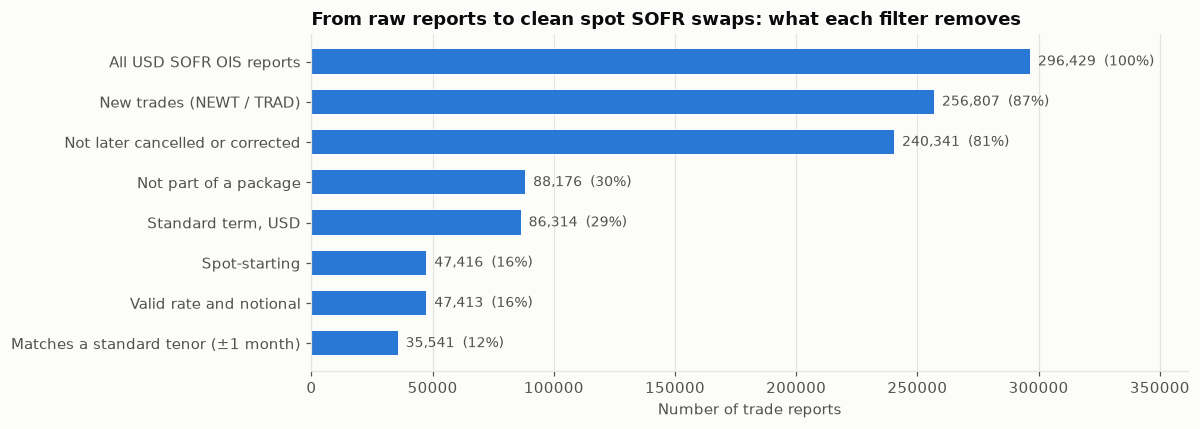

In [6]:
# --- Chart 1: the cleaning funnel
fig, ax = plt.subplots(figsize=(11, 4))
ax.set_axisbelow(True)
bars = ax.barh(
    funnel["step"][::-1], funnel["trades"][::-1], color=PALETTE[0], height=0.6
)
for bar, (n, pct) in zip(bars, funnel[["trades", "kept_%"]][::-1].to_numpy()):
    ax.text(
        bar.get_width(),
        bar.get_y() + bar.get_height() / 2,
        f"  {n:,.0f}  ({pct:.0f}%)",
        va="center",
        color=INK_2,
        fontsize=9,
    )
ax.set_title(
    "From raw reports to clean spot SOFR swaps: what each filter removes"
)
ax.set_xlabel("Number of trade reports")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, funnel["trades"].max() * 1.22)
plt.tight_layout()
save_fig(fig, "01_cleaning_funnel")
plt.show()

## 6. Aggregate with SQL (DuckDB)

DuckDB runs SQL directly on the pandas DataFrame, with no database server and no copy. This is the same query a risk-reporting team would run on a warehouse table: activity and simple price statistics by day and tenor.

In [7]:
daily_stats = duckdb.sql("""
    SELECT trade_date,
           tenor,
           COUNT(*)                                        AS trades,
           SUM(notional) / 1e9                             AS notional_bn,
           SUM(rate_pct * notional) / SUM(notional)        AS vwap_rate_pct,
           MEDIAN(rate_pct)                                AS median_rate_pct,
           MIN(rate_pct)                                   AS min_rate_pct,
           MAX(rate_pct)                                   AS max_rate_pct,
           AVG(CASE WHEN notional_capped THEN 1 ELSE 0 END) AS share_capped
    FROM clean
    GROUP BY trade_date, tenor
    ORDER BY trade_date, tenor
""").df()

by_tenor = duckdb.sql("""
    SELECT tenor, COUNT(*) AS trades, SUM(notional) / 1e9 AS notional_bn,
           COUNT(DISTINCT trade_date) AS days_traded
    FROM clean GROUP BY tenor ORDER BY tenor
""").df()
by_tenor

,tenor,trades,notional_bn,days_traded
0,1.0000,3846,502.3356,60
1,2.0000,4533,374.0776,59
2,3.0000,2663,201.7288,60
3,4.0000,1351,51.1388,58
4,5.0000,5840,294.6303,60
5,6.0000,801,27.6104,59
6,7.0000,1702,73.7397,58
7,8.0000,413,7.5362,58
8,9.0000,601,16.3077,58
9,10.0000,7670,269.2757,60


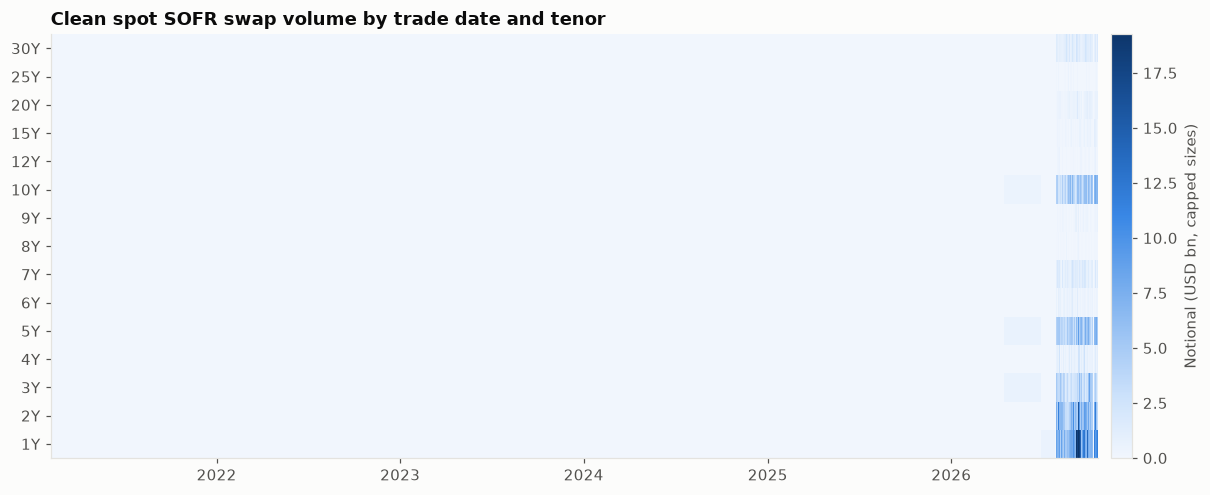

In [8]:
# --- Chart 2: where the market trades (heatmap of notional by day x tenor)
volume = daily_stats.pivot(
    index="tenor", columns="trade_date", values="notional_bn"
).reindex(STANDARD_TENORS)
fig, ax = plt.subplots(figsize=(12, 4.6))
mesh = ax.pcolormesh(
    volume.columns,
    np.arange(len(volume.index)),
    volume.fillna(0).values,
    cmap=plt.matplotlib.colors.LinearSegmentedColormap.from_list(
        "blues", BLUE_RAMP
    ),
    shading="nearest",
)
ax.set_yticks(range(len(volume.index)), [f"{t}Y" for t in volume.index])
ax.set_title("Clean spot SOFR swap volume by trade date and tenor")
ax.grid(False)
fig.colorbar(mesh, ax=ax, label="Notional (USD bn, capped sizes)", pad=0.01)
plt.tight_layout()
save_fig(fig, "02_volume_heatmap")
plt.show()

## 7. Estimate the par swap rate per day and tenor

For each (day, tenor) with at least three trades we compute the Huber M-estimate, using `statsmodels`' robust linear model with only an intercept. With fewer trades we fall back to the median and flag the point as low-confidence. Each trade's distance from the estimate, in robust standard deviations, is kept so outliers can be shown instead of silently dropped.

In [9]:
def huber_center(rates_bp: np.ndarray) -> float:
    """Huber M-estimate of location (intercept-only robust regression)."""
    if len(rates_bp) < MIN_TRADES_PER_POINT or np.ptp(rates_bp) == 0:
        return float(np.median(rates_bp))
    fit = sm.RLM(
        rates_bp, np.ones(len(rates_bp)), M=sm.robust.norms.HuberT()
    ).fit()
    return float(fit.params[0])


rows = []
for (day, tenor), grp in clean.groupby(["trade_date", "tenor"]):
    bp = grp["rate_pct"].to_numpy() * 100
    center = huber_center(bp)
    mad = (
        1.4826 * np.median(np.abs(bp - np.median(bp)))
        if len(bp) > 1
        else np.nan
    )
    rows.append({
        "trade_date": day,
        "tenor": tenor,
        "trades": len(bp),
        "par_rate_pct": center / 100,
        "robust_sd_bp": mad,
        "low_confidence": len(bp) < MIN_TRADES_PER_POINT,
    })
estimates = pd.DataFrame(rows)

# z-score of every trade against its (day, tenor) estimate
clean = clean.merge(
    estimates[["trade_date", "tenor", "par_rate_pct", "robust_sd_bp"]],
    on=["trade_date", "tenor"],
)
clean["z"] = (
    (clean["rate_pct"] - clean["par_rate_pct"])
    * 100
    / clean["robust_sd_bp"].replace(0, np.nan)
)
clean["outlier"] = clean["z"].abs() > OUTLIER_Z

LATEST = estimates["trade_date"].max()
latest = estimates[
    (estimates["trade_date"] == LATEST) & ~estimates["low_confidence"]
].set_index("tenor")
print(
    f"{len(estimates):,} day×tenor estimates ·"
    f" {clean['outlier'].sum():,} trades flagged as outliers"
    f" ({clean['outlier'].mean():.1%}) · latest day {LATEST:%Y-%m-%d} with"
    f" {len(latest)} tenors"
)
latest[["trades", "par_rate_pct", "robust_sd_bp"]]

881 day×tenor estimates · 2,204 trades flagged as outliers (6.2%) · latest day 2026-10-19 with 15 tenors


,trades,par_rate_pct,robust_sd_bp
tenor,,,
1.0000,69,4.4819,1.9570
2.0000,50,4.6121,2.0578
3.0000,40,4.6330,2.5716
4.0000,16,4.6305,2.2091
5.0000,96,4.4438,7.0223
6.0000,8,4.6358,1.6383
7.0000,25,4.6588,2.5204
8.0000,15,4.6708,3.7658
9.0000,10,4.7196,0.7339


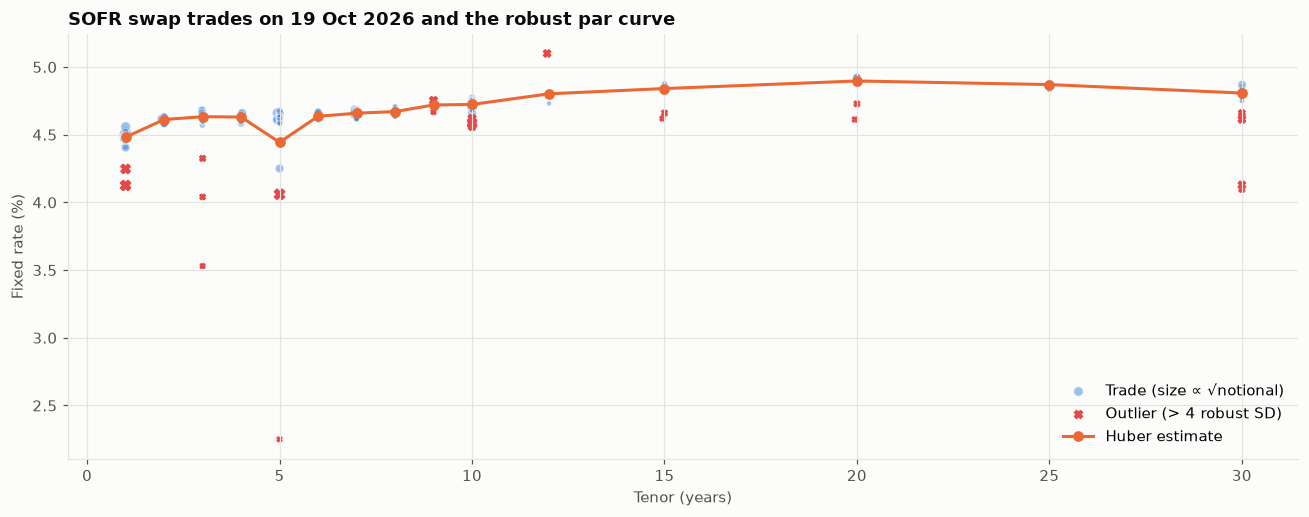

In [10]:
# --- Chart 3: every trade on the latest day vs the robust estimate
day_trades = clean[clean["trade_date"] == LATEST]
fig, ax = plt.subplots(figsize=(12, 4.8))
normal, flagged = (
    day_trades[~day_trades["outlier"]],
    day_trades[day_trades["outlier"]],
)
size = lambda n: 8 + 60 * np.sqrt(n / day_trades["notional"].max())
ax.scatter(
    normal["tenor_years"],
    normal["rate_pct"],
    s=size(normal["notional"]),
    color=PALETTE[0],
    alpha=0.45,
    edgecolor=SURFACE,
    linewidth=0.8,
    label="Trade (size ∝ √notional)",
)
ax.scatter(
    flagged["tenor_years"],
    flagged["rate_pct"],
    s=size(flagged["notional"]),
    color=PALETTE[7],
    marker="X",
    label=f"Outlier (> {OUTLIER_Z:.0f} robust SD)",
)
ax.plot(
    latest.index,
    latest["par_rate_pct"],
    color=PALETTE[1],
    marker="o",
    ms=6,
    label="Huber estimate",
)
ax.set_title(f"SOFR swap trades on {LATEST:%d %b %Y} and the robust par curve")
ax.set_xlabel("Tenor (years)")
ax.set_ylabel("Fixed rate (%)")
ax.legend(loc="lower right")
plt.tight_layout()
save_fig(fig, "03_latest_day_trades_vs_estimate")
plt.show()

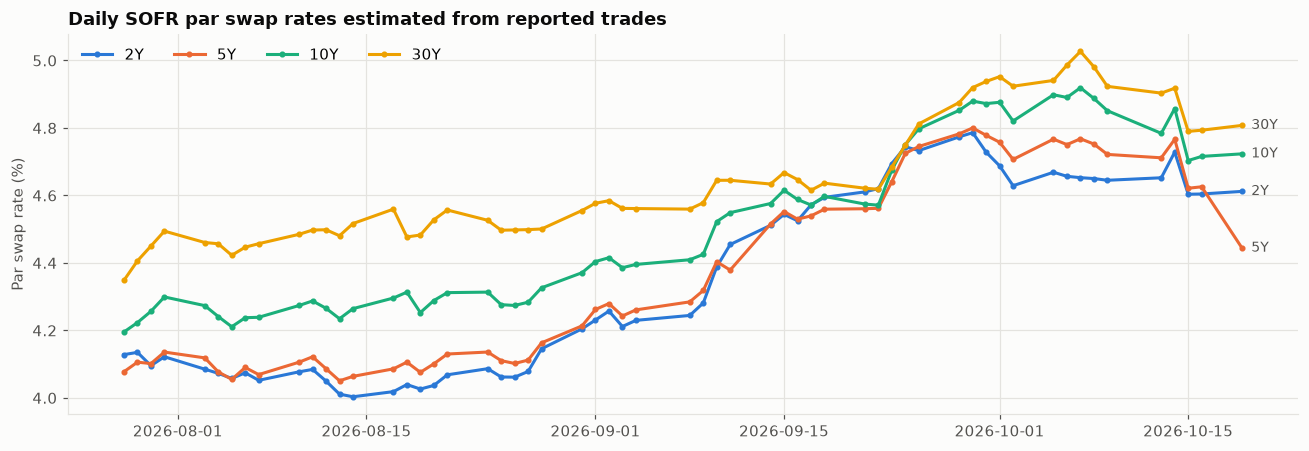

In [11]:
# --- Chart 4: history of the key swap rates over the window
KEY_TENORS = [2, 5, 10, 30]
history = estimates[
    ~estimates["low_confidence"] & estimates["tenor"].isin(KEY_TENORS)
].pivot(index="trade_date", columns="tenor", values="par_rate_pct")
fig, ax = plt.subplots(figsize=(12, 4.2))
for i, tenor in enumerate(KEY_TENORS):
    if tenor in history:
        s = history[tenor].dropna()
        ax.plot(
            s.index,
            s.values,
            color=PALETTE[i],
            marker="o",
            ms=3,
            label=f"{tenor}Y",
        )
        ax.annotate(
            f"{tenor}Y",
            (s.index[-1], s.values[-1]),
            xytext=(6, 0),
            textcoords="offset points",
            color=INK_2,
            va="center",
            fontsize=9,
        )
ax.set_title("Daily SOFR par swap rates estimated from reported trades")
ax.set_ylabel("Par swap rate (%)")
ax.legend(ncol=4, loc="upper left")
plt.tight_layout()
save_fig(fig, "04_swap_rate_history")
plt.show()

## 8. Bootstrap the curve and compare with Treasuries

The latest day's robust par rates become QuantLib OIS helpers, anchored at the overnight SOFR fixing. We use monotone-convex interpolation, which combines smooth forwards with good locality.

We then put the Treasury par curve of the same day next to it. The gap between the two is the **observed swap spread**, the number a public-data curve has to assume.

In [12]:
fred = Fred(api_key=FRED_API_KEY)
sofr_series = cached(
    "fred_sofr",
    lambda: fred.get_series(
        "SOFR", observation_start=LATEST - pd.Timedelta(days=60)
    )
    .dropna()
    .rename("sofr")
    .rename_axis("date")
    .reset_index(),
).set_index("date")["sofr"]
sofr_on = float(sofr_series.loc[:LATEST].iloc[-1])

ql_today = ql.Date(LATEST.day, LATEST.month, LATEST.year)
ql.Settings.instance().evaluationDate = ql_today
sofr_index = ql.Sofr()

helpers = [
    ql.DepositRateHelper(
        ql.QuoteHandle(ql.SimpleQuote(sofr_on / 100)), sofr_index
    )
]
for tenor, row in latest.iterrows():
    helpers.append(
        ql.OISRateHelper(
            2,
            ql.Period(int(tenor), ql.Years),
            ql.QuoteHandle(ql.SimpleQuote(row["par_rate_pct"] / 100)),
            sofr_index,
        )
    )
dtcc_curve = ql.PiecewiseConvexMonotoneForward(
    ql_today, helpers, ql.Actual365Fixed()
)
dtcc_curve.enableExtrapolation()
# trigger the bootstrap now
dtcc_curve.discount(ql_today + ql.Period(1, ql.Years))


def zero_pct(curve, years):
    return (
        curve.zeroRate(
            ql_today + ql.Period(int(round(years * 12)), ql.Months),
            ql.Actual365Fixed(),
            ql.Continuous,
        ).rate()
        * 100
    )


max_err = max(abs(h.impliedQuote() - h.quote().value()) for h in helpers) * 1e4
print(
    f"SOFR fixing {sofr_on:.2f}% · {len(helpers) - 1} swap tenors · max"
    f" repricing error {max_err:.6f} bp"
)

SOFR fixing 3.89% · 15 swap tenors · max repricing error 0.000000 bp


In [13]:
TREASURY_URL = (
    "https://home.treasury.gov/resource-center/data-chart-center/interest-rates/"
    "daily-treasury-rates.csv/{year}/all?type=daily_treasury_yield_curve"
    "&field_tdr_date_value={year}&page&_format=csv"
)


def tenor_in_years(col):
    m = re.match(r"^\s*([\d.]+)\s*(Mo|Month|Yr|Year)", col)
    return (
        None
        if not m
        else float(m.group(1)) / (12 if m.group(2).startswith("Mo") else 1)
    )


def fetch_treasury() -> pd.DataFrame:
    text = requests.get(
        TREASURY_URL.format(year=LATEST.year),
        headers=BROWSER_HEADERS,
        timeout=30,
    ).text
    raw = pd.read_csv(io.StringIO(text))
    raw["date"] = pd.to_datetime(raw["Date"], format="%m/%d/%Y")
    cols = {
        c: tenor_in_years(c)
        for c in raw.columns
        if tenor_in_years(c) is not None
    }
    long = raw.melt(
        id_vars="date",
        value_vars=list(cols),
        var_name="column",
        value_name="par_yield",
    )
    long["tenor"] = long["column"].map(cols)
    return long[["date", "tenor", "par_yield"]].dropna()


treasury = cached("treasury_par_curves", fetch_treasury).pivot(
    index="date", columns="tenor", values="par_yield"
)
ust_day = treasury.loc[:LATEST].iloc[-1].dropna()

# Swap spread = SOFR par swap rate − Treasury par yield at the same tenor (bp)
spreads = latest[["par_rate_pct"]].copy()
spreads["treasury_par_pct"] = np.interp(
    spreads.index.astype(float), ust_day.index.astype(float), ust_day.values
)
spreads["observed_swap_spread_bp"] = (
    spreads["par_rate_pct"] - spreads["treasury_par_pct"]
) * 100

# The textbook swap-spread assumption used by curves built without swap data
TEXTBOOK_SPREAD_BP = {
    2: -15,
    3: -20,
    5: -25,
    7: -30,
    10: -40,
    15: -55,
    20: -65,
    30: -75,
}
spreads["textbook_assumption_bp"] = [
    TEXTBOOK_SPREAD_BP.get(int(t), np.nan) for t in spreads.index
]
spreads.round(2)

,par_rate_pct,treasury_par_pct,observed_swap_spread_bp,textbook_assumption_bp
tenor,,,,
1.0000,4.4800,4.4600,2.1900,NaN
2.0000,4.6100,4.7400,-12.7900,-15.0000
3.0000,4.6300,4.8200,-18.7000,-20.0000
4.0000,4.6300,4.8600,-22.4500,NaN
5.0000,4.4400,4.8900,-44.6200,-25.0000
6.0000,4.6400,4.9400,-29.9200,NaN
7.0000,4.6600,4.9800,-32.1200,-30.0000
8.0000,4.6700,5.0200,-34.5900,NaN
9.0000,4.7200,5.0500,-33.3700,NaN


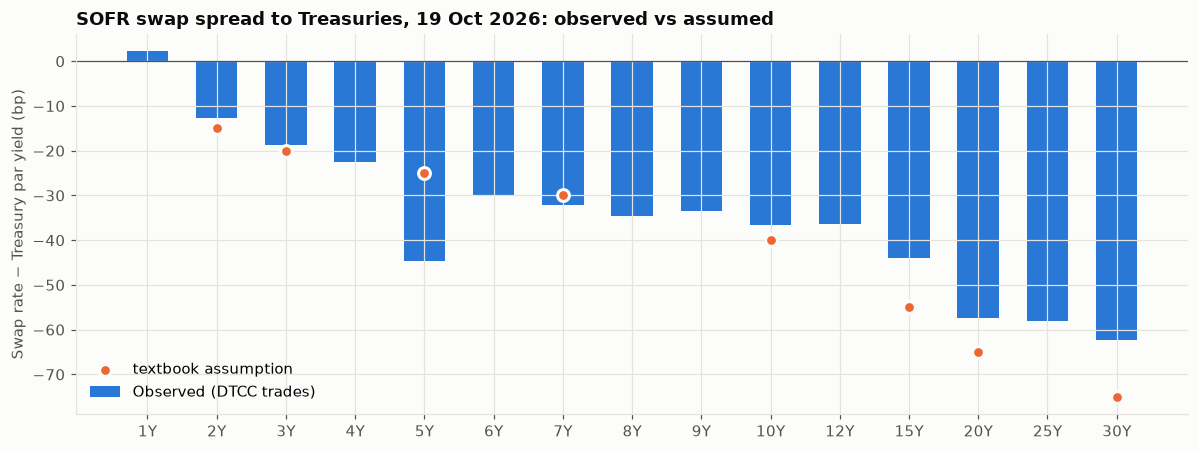

In [14]:
# --- Chart 5: observed swap spreads vs the textbook assumption
fig, ax = plt.subplots(figsize=(11, 4.2))
x = np.arange(len(spreads))
ax.bar(
    x,
    spreads["observed_swap_spread_bp"],
    width=0.6,
    color=PALETTE[0],
    label="Observed (DTCC trades)",
)
has_assumption = spreads["textbook_assumption_bp"].notna().to_numpy()
ax.scatter(
    x[has_assumption],
    spreads["textbook_assumption_bp"][has_assumption],
    color=PALETTE[1],
    s=60,
    zorder=3,
    edgecolor=SURFACE,
    linewidth=2,
    label="textbook assumption",
)
ax.axhline(0, color=INK_2, lw=0.8)
ax.set_xticks(x, [f"{t:g}Y" for t in spreads.index])
ax.set_title(
    f"SOFR swap spread to Treasuries, {LATEST:%d %b %Y}: observed vs assumed"
)
ax.set_ylabel("Swap rate − Treasury par yield (bp)")
ax.legend()
plt.tight_layout()
save_fig(fig, "05_observed_swap_spreads")
plt.show()

In [15]:
# --- The trade-based curve at the key tenors
key_tenors = [t for t in (2, 3, 5, 7, 10, 20, 30) if t <= latest.index.max()]
key_points = pd.DataFrame({
    "tenor": key_tenors,
    "dtcc_zero_%": [zero_pct(dtcc_curve, t) for t in key_tenors],
})
key_points.round(3)

,tenor,dtcc_zero_%
0,2,4.5700
1,3,4.5920
2,5,4.3910
3,7,4.6260
4,10,4.6970
5,20,4.9060
6,30,4.7230


## 9. Dashboard

In [16]:
grid_years = np.arange(0.25, latest.index.max() + 0.01, 0.25)
zero_line = [zero_pct(dtcc_curve, t) for t in grid_years]

dash = make_subplots(
    rows=2,
    cols=2,
    vertical_spacing=0.14,
    horizontal_spacing=0.08,
    subplot_titles=(
        f"Trade-based SOFR curve · {LATEST:%d %b %Y}",
        "Key par swap rates over the window",
        "Clean notional traded by tenor (USD bn)",
        "Observed swap spread to Treasuries (bp)",
    ),
)
dash.add_trace(
    go.Scatter(
        x=day_trades["tenor_years"],
        y=day_trades["rate_pct"],
        mode="markers",
        name="Trades",
        marker=dict(color=PALETTE[0], size=5, opacity=0.35),
    ),
    1,
    1,
)
dash.add_trace(
    go.Scatter(
        x=latest.index,
        y=latest["par_rate_pct"],
        name="Par (Huber)",
        mode="lines+markers",
        line=dict(color=PALETTE[1], width=2),
    ),
    1,
    1,
)
dash.add_trace(
    go.Scatter(
        x=grid_years,
        y=zero_line,
        name="Zero (bootstrapped)",
        line=dict(color=PALETTE[2], width=2, dash="dot"),
    ),
    1,
    1,
)
for i, tenor in enumerate(KEY_TENORS):
    if tenor in history:
        dash.add_trace(
            go.Scatter(
                x=history.index,
                y=history[tenor],
                name=f"{tenor}Y",
                line=dict(color=PALETTE[i], width=2),
            ),
            1,
            2,
        )
dash.add_trace(
    go.Bar(
        x=[f"{t:g}Y" for t in by_tenor["tenor"]],
        y=by_tenor["notional_bn"],
        name="Notional",
        marker_color=PALETTE[0],
        showlegend=False,
    ),
    2,
    1,
)
dash.add_trace(
    go.Bar(
        x=[f"{t:g}Y" for t in spreads.index],
        y=spreads["observed_swap_spread_bp"],
        name="Observed spread",
        marker_color=PALETTE[0],
        showlegend=False,
    ),
    2,
    2,
)
dash.add_trace(
    go.Scatter(
        x=[f"{t:g}Y" for t in spreads.index],
        y=spreads["textbook_assumption_bp"],
        mode="markers",
        name="textbook assumption",
        marker=dict(color=PALETTE[1], size=10),
    ),
    2,
    2,
)

kpis = (
    f"{len(clean):,} clean trades from"
    f" {raw_reports['file_date'].nunique()} days · 10Y swap"
    f" {latest['par_rate_pct'].get(10.0, np.nan):.3f}% · 10Y spread"
    f" {spreads['observed_swap_spread_bp'].get(10.0, np.nan):+.0f} bp ·"
    f" outliers flagged {clean['outlier'].mean():.1%}"
)
dash.update_layout(
    title=dict(
        text=(
            "<b>SOFR swap market from DTCC trade reports</b><br>"
            f"<span style='font-size:13px;color:{INK_2}'>{kpis}</span>"
        ),
        x=0.01,
    ),
    height=860,
    width=1300,
    template="plotly_white",
    paper_bgcolor=SURFACE,
    plot_bgcolor=SURFACE,
    font=dict(color=INK_2),
    legend=dict(orientation="h", y=-0.07),
    margin=dict(t=110),
)
dash.write_html(OUT_DIR / "dashboard.html", include_plotlyjs="cdn")
try:
    dash.write_image(OUT_DIR / "dashboard.png", scale=2)
    print("Dashboard saved: outputs/dashboard.html and .png")
except Exception as err:
    print(
        f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
        " `plotly_get_chrome` once."
    )

estimates.to_csv(OUT_DIR / "dtcc_par_rate_estimates.csv", index=False)
dash.show()

Dashboard saved: outputs/dashboard.html and .png


## 10. Reading the results

- **Most reports never make it into the curve, and that is the point.** The funnel shows how much of the raw tape is lifecycle events, corrections, package legs and forward starts. A naïve average over raw reports would mix all of those.
- **Liquidity is concentrated.** The volume heatmap shows where the curve is genuinely observed (typically 1–10Y and 30Y) and where it is interpolated. Tenors with few trades are the ones to challenge in a model validation.
- **Swap spreads are observed, not assumed.** Chart 5 compares real spreads with the textbook assumption. Any systematic gap is a direct, quantified model-risk finding about the public-data curve.

## 11. Limitations and extensions

- **Capped notionals.** Large trades are published with a capped size, so volume-weighting underweights the biggest prints. The robust estimate does not depend on size, which limits the damage.
- **Timing.** Trades from the whole day are pooled. An intraday version would weight trades close to the 4 pm curve snapshot more heavily.
- **Unmatched corrections are dropped, not re-applied.** A production ETL would replay `CORR`/`MODI` messages onto the original trade instead of discarding both.
- **Only 1–30Y.** Sub-1Y SOFR swaps are reported too. Adding them, plus the SOFR futures strip, would give a complete hybrid curve.

## References

### Finance and regulation

- Jermann, U. J. (2020). Negative swap spreads and limited arbitrage. *The Review of Financial Studies, 33*(1), 212–238. https://doi.org/10.1093/rfs/hhz030
- Hagan, P. S., & West, G. (2006). Interpolation methods for curve construction. *Applied Mathematical Finance, 13*(2), 89–129. https://doi.org/10.1080/13504860500396032
- Huber, P. J. (1964). Robust estimation of a location parameter. *The Annals of Mathematical Statistics, 35*(1), 73–101. https://doi.org/10.1214/aoms/1177703732
- Schrimpf, A., & Sushko, V. (2019). Beyond LIBOR: A primer on the new benchmark rates. *BIS Quarterly Review*, March, 29–52. https://www.bis.org/publ/qtrpdf/r_qt1903e.htm

### Machine learning and deep learning

- Raasveldt, M., & Mühleisen, H. (2019). DuckDB: An embeddable analytical database. In *Proceedings of the 2019 International Conference on Management of Data*. https://doi.org/10.1145/3299869.3320212
- Rousseeuw, P. J., & Leroy, A. M. (1987). *Robust regression and outlier detection*. Wiley. https://doi.org/10.1002/0471725382